# 实验三 利用Pandas进行数据清洗
例3-1至例3-21。随机数种子固定为20261010。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy import nan as NA
from IPython.display import display
%matplotlib inline
np.random.seed(20261010)
print('Python 与库版本：')
import sys
print(sys.version.split()[0], 'pandas', pd.__version__,
      'numpy', np.__version__)


Python 与库版本：
3.13.2 pandas 2.3.3 numpy 2.3.5


In [2]:
# 例3-1 利用isnull()函数检测缺失值
string_data = pd.Series(
    ['aardvark', 'artichoke', np.nan, 'avocado'])
print(string_data)
string_data.isnull()

0     aardvark
1    artichoke
2          NaN
3      avocado
dtype: object


0    False
1    False
2     True
3    False
dtype: bool

In [3]:
# 例3-2 Series中的None值处理
string_data = pd.Series(
    ['aardvark', 'artichoke', None, 'avocado'])
string_data.isnull()

0    False
1    False
2     True
3    False
dtype: bool

In [4]:
# 例3-3 统计缺失值
df = pd.DataFrame(np.arange(12).reshape(3, 4),
                  columns=['A', 'B', 'C', 'D'])
df.iloc[2, :] = np.nan
df[3] = np.nan
print(df)
df.isnull().sum()

     A    B    C    D   3
0  0.0  1.0  2.0  3.0 NaN
1  4.0  5.0  6.0  7.0 NaN
2  NaN  NaN  NaN  NaN NaN


A    1
B    1
C    1
D    1
3    3
dtype: int64

In [5]:
# 例3-4 查看DataFrame的缺失情况
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A       2 non-null      float64
 1   B       2 non-null      float64
 2   C       2 non-null      float64
 3   D       2 non-null      float64
 4   3       0 non-null      float64
dtypes: float64(5)
memory usage: 252.0 bytes


In [6]:
# 例3-5 Series的dropna()函数
data = pd.Series([1, NA, 3.5, NA, 7])
print(data)
print(data.dropna())

0    1.0
1    NaN
2    3.5
3    NaN
4    7.0
dtype: float64
0    1.0
2    3.5
4    7.0
dtype: float64


In [7]:
# 例3-6 布尔型索引过滤非缺失值
not_null = data.notnull()
print(not_null)
print(data[not_null])

0     True
1    False
2     True
3    False
4     True
dtype: bool
0    1.0
2    3.5
4    7.0
dtype: float64


In [8]:
# 例3-7 DataFrame默认删除含缺失值的行
data = pd.DataFrame([[1, 5.5, 3], [1, NA, NA],
                     [NA, NA, NA], [NA, 5.5, 3]])
print(data)
cleaned = data.dropna()
print('删除缺失值后的：')
print(cleaned)

     0    1    2
0  1.0  5.5  3.0
1  1.0  NaN  NaN
2  NaN  NaN  NaN
3  NaN  5.5  3.0
删除缺失值后的：
     0    1    2
0  1.0  5.5  3.0


In [9]:
# 例3-8 删除全部为缺失值的行
data = pd.DataFrame([[1, 5.5, 3], [1, NA, NA],
                     [NA, NA, NA], [NA, 5.5, 3]])
print(data)
print(data.dropna(how='all'))

     0    1    2
0  1.0  5.5  3.0
1  1.0  NaN  NaN
2  NaN  NaN  NaN
3  NaN  5.5  3.0
     0    1    2
0  1.0  5.5  3.0
1  1.0  NaN  NaN
3  NaN  5.5  3.0


In [10]:
# 例3-9 删除全部为缺失值的列
data = pd.DataFrame([[1, 5.5, NA], [1, NA, NA],
                     [NA, NA, NA], [NA, 5.5, NA]])
print(data)
print(data.dropna(axis=1, how='all'))

     0    1   2
0  1.0  5.5 NaN
1  1.0  NaN NaN
2  NaN  NaN NaN
3  NaN  5.5 NaN
     0    1
0  1.0  5.5
1  1.0  NaN
2  NaN  NaN
3  NaN  5.5


In [11]:
# 例3-10 thresh参数：至少保留两个非缺失值
df = pd.DataFrame(np.random.randn(7, 3))
df.iloc[:4, 1] = NA
df.iloc[:2, 2] = NA
print(df)
print(df.dropna(thresh=2))

          0         1         2
0  0.701602       NaN       NaN
1 -0.228506       NaN       NaN
2 -0.522128       NaN -0.441479
3 -0.606593       NaN -0.270032
4 -1.149448 -0.499732  0.637415
5  0.213513 -0.532266 -0.713801
6 -0.334013 -0.661498  1.038343
          0         1         2
2 -0.522128       NaN -0.441479
3 -0.606593       NaN -0.270032
4 -1.149448 -0.499732  0.637415
5  0.213513 -0.532266 -0.713801
6 -0.334013 -0.661498  1.038343


In [12]:
# 例3-11 通过字典形式填充缺失值
df = pd.DataFrame(np.random.randn(5, 3))
df.iloc[:3, 1] = NA
df.iloc[:2, 2] = NA
print(df)
print(df.fillna({1: 0.88, 2: 0.66}))

          0         1         2
0  1.276492       NaN       NaN
1 -0.194950       NaN       NaN
2 -0.462225       NaN -0.094852
3 -1.912384 -0.757944 -0.375152
4 -1.753676 -1.068220 -0.040080
          0         1         2
0  1.276492  0.880000  0.660000
1 -0.194950  0.880000  0.660000
2 -0.462225  0.880000 -0.094852
3 -1.912384 -0.757944 -0.375152
4 -1.753676 -1.068220 -0.040080


In [13]:
# 例3-12 前向填充缺失值
df = pd.DataFrame(np.random.randn(6, 3))
df.iloc[2:, 1] = NA
df.iloc[4:, 2] = NA
print(df)
# ffill()与教材fillna(method='ffill')含义相同
print(df.ffill())

          0         1         2
0  0.465058 -0.342196  1.834108
1  0.655279  0.665115 -1.341445
2  1.019629       NaN  0.084440
3 -0.539039       NaN  0.416504
4  2.041474       NaN       NaN
5 -0.303240       NaN       NaN
          0         1         2
0  0.465058 -0.342196  1.834108
1  0.655279  0.665115 -1.341445
2  1.019629  0.665115  0.084440
3 -0.539039  0.665115  0.416504
4  2.041474  0.665115  0.416504
5 -0.303240  0.665115  0.416504


In [14]:
# 例3-13 用Series的均值填充缺失值
data = pd.Series([1, NA, 3.5, NA, 7])
data.fillna(data.mean())

0    1.000000
1    3.833333
2    3.500000
3    3.833333
4    7.000000
dtype: float64

In [15]:
# 例3-14 DataFrame中用均值填充
df = pd.DataFrame(np.random.randn(4, 3))
df.iloc[2:, 1] = NA
df.iloc[3:, 2] = NA
print(df)
# 按列赋值，使填充结果明确写回DataFrame
df[1] = df[1].fillna(df[1].mean())
print(df)

          0         1         2
0  2.008268 -1.329666  2.752220
1  0.160448 -2.148865 -2.306139
2 -0.749448       NaN  0.835857
3 -0.611520       NaN       NaN
          0         1         2
0  2.008268 -1.329666  2.752220
1  0.160448 -2.148865 -2.306139
2 -0.749448 -1.739266  0.835857
3 -0.611520 -1.739266       NaN


In [16]:
# 例3-15 将空字符串替换为“不详”
data = {'姓名': ['张三', '小明', '马芳', '国志'],
        '性别': ['0', '1', '0', '1'],
        '籍贯': ['北京', '甘肃', '', '上海']}
df = pd.DataFrame(data)
df = df.replace('', '不详')
print(df)

   姓名 性别  籍贯
0  张三  0  北京
1  小明  1  甘肃
2  马芳  0  不详
3  国志  1  上海


In [17]:
# 例3-16 传入列表实现多值替换
df = df.replace(['不详', '甘肃'], ['兰州', '兰州'])
print(df)

   姓名 性别  籍贯
0  张三  0  北京
1  小明  1  兰州
2  马芳  0  兰州
3  国志  1  上海


In [18]:
# 例3-17 传入字典实现多值替换
df = df.replace({'1': '男', '0': '女'})
print(df)

   姓名 性别  籍贯
0  张三  女  北京
1  小明  男  兰州
2  马芳  女  兰州
3  国志  男  上海


In [19]:
# 例3-18 map()函数映射成绩等级
data = {'姓名': ['张三', '小明', '马芳', '国志'],
        '性别': ['0', '1', '0', '1'],
        '籍贯': ['北京', '兰州', '兰州', '上海']}
df = pd.DataFrame(data)
df['成绩'] = [58, 86, 91, 78]
print(df)
def grade(score):
    if score >= 90:
        return '优'
    elif score >= 70:
        return '良'
    elif score >= 60:
        return '中'
    else:
        return '差'
df['等级'] = df['成绩'].map(grade)
print(df)

   姓名 性别  籍贯  成绩
0  张三  0  北京  58
1  小明  1  兰州  86
2  马芳  0  兰州  91
3  国志  1  上海  78
   姓名 性别  籍贯  成绩 等级
0  张三  0  北京  58  差
1  小明  1  兰州  86  良
2  马芳  0  兰州  91  优
3  国志  1  上海  78  良


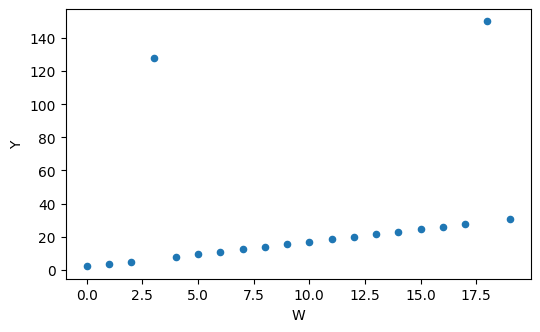

In [20]:
# 例3-19 利用散点图检测异常值
wdf = pd.DataFrame(np.arange(20), columns=['W'])
wdf['Y'] = wdf['W'] * 1.5 + 2
wdf.iloc[3, 1] = 128
wdf.iloc[18, 1] = 150
wdf.plot(kind='scatter', x='W', y='Y', figsize=(6, 3.5))
plt.show()

max = 30.5 ; min = 2.0
离群点的索引是：
Index([3, 18], dtype='int64')


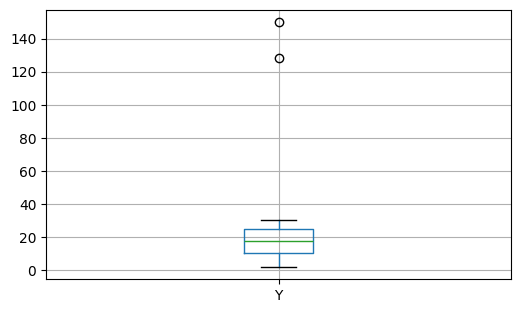

In [21]:
# 例3-20 利用箱线图分析异常值
fig = wdf.boxplot(column=['Y'], return_type='dict',
                  figsize=(6, 3.5))
minimum = fig['caps'][0].get_ydata()[0]
maximum = fig['caps'][1].get_ydata()[0]
print('max =', maximum, '; min =', minimum)
print('离群点的索引是：')
print(wdf[(wdf['Y'] < minimum) | (wdf['Y'] > maximum)].index)
plt.show()

In [22]:
# 例3-21 利用3σ法则检测异常值
def outRange(s):
    mask = ((s.mean() - 3 * s.std() > s)
            | (s.mean() + 3 * s.std() < s))
    return s.loc[mask]
outier = outRange(wdf['Y'])
outier

18    150.0
Name: Y, dtype: float64